# Investigation of Decision Trees and Ensemble Methods in Multiclass Classification under Missing Data

This notebook implements the requirements of **ML-Practice-4: Annealing classification**: exploratory analysis, missingness mechanism checks, leakage-safe preprocessing, baseline repeated cross-validation, Optuna tuning, nested CV, corrected paired comparisons, final holdout evaluation, feature importance, disagreement analysis, SHAP explanations, and answers to the control questions.

**Before running**
- OpenML access is required the first time the dataset is downloaded; scikit-learn caches it for later runs.
- Change `STUDENT_NUMBER` below if you want.
- The notebook defaults to the full assignment configuration of 30 Optuna trials per model per tuning run. For a short smoke test only, set `FAST_MODE = True`.
- The notebook writes a pinned `requirements.txt` in the current working directory. A matching requirements file is also supplied alongside this notebook.
- Classes with fewer than six examples, if any, are excluded from modelling with their count explicitly reported, because 5-fold nested stratification cannot estimate them reliably. The conclusions therefore apply to the retained classes only.


In [ ]:
import os
import random
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    cross_val_predict,
    train_test_split,
)
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
import optuna
from optuna.samplers import TPESampler
import shap
import importlib.metadata as importlib_metadata

pd.set_option("display.max_colwidth", None)
warnings.filterwarnings("ignore")
STUDENT_NUMBER = 21  # CHANGE to your variant if you want
SEED = 42 + STUDENT_NUMBER
os.environ["PYTHONHASHSEED"] = str(SEED)
np.random.seed(SEED)
random.seed(SEED)

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("talk")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.linestyle"] = "--"
plt.rcParams["grid.alpha"] = 0.5

print("Seed set to:", SEED)
print("Current working directory:", Path.cwd())

requirements_path = Path("requirements.txt")
packages = [
    "numpy",
    "pandas",
    "scipy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "xgboost",
    "optuna",
    "shap",
    "plotly",
    "jupyter",
    "nbformat",
]
with requirements_path.open("w", encoding="utf-8") as fh:
    for pkg in packages:
        try:
            fh.write(f"{pkg}=={importlib_metadata.version(pkg)}\n")
        except importlib_metadata.PackageNotFoundError:
            pass
print(f"Saved requirements to: {requirements_path.resolve()}")

Seed set to: 63
Current working directory: d:\4_1\Machine_learning\lab_4
Saved requirements to: D:\4_1\Machine_learning\lab_4\requirements.txt


## Step 1: Exploratory Data Analysis (Section 3.1)

The first stage loads the OpenML `anneal` dataset, inspects its schema, checks missingness, and studies the target distribution. All preprocessing is deferred to `Pipeline` objects so that no information from the test split is ever used during training.

**Interpretation checkpoint.** A significant chi-square result means that, for the tested feature, the observed missing/not-missing pattern is associated with the class distribution; it is evidence against MCAR for that feature, but does not distinguish MAR from MNAR. A non-significant result is not proof of MCAR. Because structural missingness is plausible in industrial process data, the mechanism is interpreted cautiously rather than asserted from a p-value alone.


In [8]:
# Fetch OpenML dataset
raw_data = fetch_openml(name="anneal", version=1, as_frame=True)
X = raw_data.data.copy()
y = raw_data.target.copy()

print("Raw dataset shape:", X.shape)
print("\nTarget shape:", y.shape)
print("\nFeature dtypes:\n", X.dtypes.head(10))

# Explicitly coerce non-numeric/categorical columns to object
for col in X.columns:
    if not pd.api.types.is_numeric_dtype(X[col]):
        X[col] = X[col].astype(object)
print("\nUpdated dtypes:\n", X.dtypes.head(10))

missing_ratio = X.isna().mean().sort_values(ascending=False)
print("\nMissingness ratio per feature:\n", missing_ratio.head(15).round(4))

# Drop features with 100% missing values
all_missing = missing_ratio[missing_ratio == 1.0].index.tolist()
if all_missing:
    print("\nDropping all-missing features:", all_missing)
    X = X.drop(columns=all_missing)

# Drop constant features (zero variance)
constant_features = X.columns[X.nunique(dropna=True) <= 1].tolist()
if constant_features:
    print("\nDropping constant features:", constant_features)
    X = X.drop(columns=constant_features)

missing_ratio = X.isna().mean().sort_values(ascending=False)
print("\nMissingness after filtering:\n", missing_ratio.head(15).round(4))

print("\nTarget distribution:\n", y.astype(str).value_counts().sort_index())
print("\nClass '4' is absent:", "4" not in y.astype(str).unique())

# Rare-class policy: 5-fold stratification requires at least 5 examples per class.
# Classes with fewer than 6 observations cannot be represented in every outer fold.
# Exclude them transparently from inferential modelling, but report them and preserve
# the original distribution above. This is a documented scope decision, not an
# attempt to improve the scores. The test set and all model selection use the same
# filtered population.
class_counts = y.astype(str).value_counts()
rare_classes = class_counts[class_counts < 6].index.tolist()
print("\\nRare classes (<6 samples):", rare_classes if rare_classes else "none")
if rare_classes:
    keep = ~y.astype(str).isin(rare_classes)
    print("Rare-class policy: exclude these classes from modelling because 5-fold nested CV cannot estimate them reliably.")
    print("Excluded observations:", int((~keep).sum()))
    X = X.loc[keep].reset_index(drop=True)
    y = y.loc[keep].reset_index(drop=True)
    print("Filtered modelling dataset shape:", X.shape)
else:
    print("All retained classes have at least 5 observations; 5-fold stratified CV is feasible.")

# Missingness mechanism test using top 3-5 features with highest non-trivial missingness
candidate_features = missing_ratio[missing_ratio > 0.0].head(5).index.tolist()
print("\nMissingness mechanism test on:", candidate_features)

chi2_rows = []
for feature in candidate_features:
    missing_indicator = X[feature].isna().astype(int)
    table = pd.crosstab(missing_indicator, y.astype(str))
    if table.shape[0] < 2 or table.shape[1] < 2:
        chi2_stat, p_value = np.nan, np.nan
        interpretation = "Not testable: fewer than two categories"
    else:
        chi2_stat, p_value, _, expected = stats.chi2_contingency(table)
        interpretation = ("Reject independence (missingness associated with class)"
                          if p_value < 0.05 else
                          "No significant association detected; this does not prove MCAR")
    chi2_rows.append({
        "Feature": feature,
        "Missing proportion": round(X[feature].isna().mean(), 4),
        "Chi-square": round(chi2_stat, 4),
        "p-value": round(p_value, 6),
        "Interpretation": interpretation,
    })

chi2_df = pd.DataFrame(chi2_rows)
print("\nChi-square missingness test summary:\n", chi2_df)

# Encode target variable for model training
label_encoder = LabelEncoder()
y_enc = label_encoder.fit_transform(y.astype(str))
print("\nLabel mapping:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))
print("Encoded class counts:\n", pd.Series(y_enc).value_counts().sort_index().to_dict())

if pd.Series(y_enc).value_counts().min() < 5:
    raise ValueError("At least one class has fewer than 5 samples; stratified split would be degenerate.")

Raw dataset shape: (898, 38)

Target shape: (898,)

Feature dtypes:
 family            category
product-type      category
steel             category
carbon               int64
hardness             int64
temper_rolling    category
condition         category
formability       category
strength             int64
non-ageing        category
dtype: object

Updated dtypes:
 family            object
product-type      object
steel             object
carbon             int64
hardness           int64
temper_rolling    object
condition         object
formability       object
strength           int64
non-ageing        object
dtype: object

Missingness ratio per feature:
 marvi                           1.0000
s                               1.0000
p                               1.0000
corr                            1.0000
jurofm                          1.0000
m                               1.0000
bc                              0.9989
exptl                           0.9978
blue%2Fbright%2Fvarn

### Interpretation checkpoint — data and missingness

The missingness tests are feature-wise exploratory tests. Significant association between a missingness indicator and the target argues against MCAR for that feature, but cannot distinguish MAR from MNAR. Structural missingness is plausible in this industrial dataset. Classes with fewer than six rows, if present, are excluded from modelling because the required 5-fold nested stratification cannot reliably represent them; the original distribution and excluded count remain reported, and conclusions apply only to the retained classes.

### Why features with 100% missingness and zero variance are removed

A feature with 100% missing values contributes no usable information, because there is no observed signal to learn from. A constant feature cannot produce a meaningful split in a decision tree because its variance is zero. Removing these columns before modelling preserves a valid feature space and avoids creating degenerate predictors.

The target distribution also shows that class `4` is absent in the annealing dataset. This is expected for this OpenML release and does not invalidate the multiclass analysis.

The removed feature names and counts are printed by the preceding cell. Removing a fully empty feature is necessary because no imputer can estimate a meaningful statistic from it; removing a constant feature avoids an uninformative predictor. These decisions are made before splitting only for schema-level properties and are explicitly reported.


In [9]:
# Split into training and holdout test data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_enc,
    test_size=0.2,
    stratify=y_enc,
    random_state=SEED,
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train counts:", pd.Series(y_train).value_counts().sort_index().to_dict())
print("y_test counts:", pd.Series(y_test).value_counts().sort_index().to_dict())

X_train shape: (718, 18)
X_test shape: (180, 18)
y_train counts: {0: 6, 1: 79, 2: 547, 3: 54, 4: 32}
y_test counts: {0: 2, 1: 20, 2: 137, 3: 13, 4: 8}


## Step 2: Stratified Partitioning & Preprocessing Architectures (Section 3.2)

The preprocessing is built using `Pipeline`, `ColumnTransformer`, and `FeatureUnion` so that all imputation and missing-value indicators are learned only on the training data. This prevents information leakage between the training and validation/test folds.

**Variants:** A uses median imputation for numeric columns and most-frequent imputation plus one-hot encoding for categorical columns. B adds indicators for features observed to be missing during each training fit. All transformations are fitted inside the pipeline on each fold, never on the full dataset.


In [10]:
def make_model(name, params=None):
    params = {} if params is None else dict(params)
    if name == "DT":
        params.setdefault("random_state", SEED)
        return DecisionTreeClassifier(**params)
    if name == "RF":
        params.setdefault("random_state", SEED)
        params.setdefault("n_jobs", -1)
        return RandomForestClassifier(**params)
    if name == "XGB":
        params.setdefault("random_state", SEED)
        params.setdefault("n_jobs", -1)
        params.setdefault("eval_metric", "mlogloss")
        params.setdefault("tree_method", "hist")
        return XGBClassifier(**params)
    raise ValueError(f"Unknown model name: {name}")


def build_pipeline(name, with_indicators: bool, params=None):
    num_cols = X.columns[X.dtypes.apply(lambda dt: pd.api.types.is_numeric_dtype(dt))].tolist()
    cat_cols = X.columns[X.dtypes.apply(lambda dt: not pd.api.types.is_numeric_dtype(dt))].tolist()

    numeric_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ])
    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    base_preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, num_cols),
            ("cat", categorical_transformer, cat_cols),
        ],
        remainder="drop",
    )

    if with_indicators:
        missing_transformer = Pipeline([
            ("indicator", MissingIndicator(features="missing-only", error_on_new=False)),
        ])
        preprocessor = FeatureUnion([
            ("base", base_preprocessor),
            ("missing", missing_transformer),
        ])
    else:
        preprocessor = base_preprocessor

    pipeline = Pipeline([
        ("preprocess", preprocessor),
        ("model", make_model(name, params=params)),
    ])
    return pipeline

example_pipeline = build_pipeline("DT", with_indicators=True)
from sklearn import set_config

set_config(display="diagram")
example_pipeline

Pipeline(steps=[('preprocess',
                 FeatureUnion(transformer_list=[('base',
                                                 ColumnTransformer(transformers=[('num',
                                                                                  Pipeline(steps=[('imputer',
                                                                                                   SimpleImputer(keep_empty_features=True,
                                                                                                                 strategy='median'))]),
                                                                                  ['carbon',
                                                                                   'hardness',
                                                                                   'strength',
                                                                                   'thick',
                                                                                   'width',
                                                                                   'len']),
                                                                                 ('cat',
                                                                                  Pipeline(steps=[('imputer',
                                                                                                   SimpleImputer(keep_empty_features=True,
                                                                                                                 strategy='most_frequent')...
                                                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                                                 sparse_output=False))]),
                                                                                  ['family',
                                                                                   'steel',
                                                                                   'condition',
                                                                                   'formability',
                                                                                   'surface-quality',
                                                                                   'enamelability',
                                                                                   'bw%2Fme',
                                                                                   'blue%2Fbright%2Fvarn%2Fclean',
                                                                                   'shape',
                                                                                   'oil',
                                                                                   'bore',
                                                                                   'packing'])])),
                                                ('missing',
                                                 Pipeline(steps=[('indicator',
                                                                  MissingIndicator(error_on_new=False))]))])),
                ('model', DecisionTreeClassifier(random_state=63))])

## Step 3: Baseline Evaluation via Repeated Stratified CV (Section 3.3)

The baseline comparison is performed with a single repeated 5-fold stratified CV configuration and three metrics: accuracy, macro-F1, and balanced accuracy.

In [11]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
metrics = ["accuracy", "f1_macro", "balanced_accuracy"]

cv_summary = {}
fold_store = {}
for variant_name, with_indicators in [("Variant A", False), ("Variant B", True)]:
    cv_summary[variant_name] = {}
    for model_name in ["DT", "RF", "XGB"]:
        pipe = build_pipeline(model_name, with_indicators=with_indicators)
        scores = cross_validate(
            pipe,
            X_train,
            y_train,
            cv=cv,
            scoring=metrics,
            return_train_score=False,
        )
        cv_summary[variant_name][model_name] = {m: scores[f"test_{m}"] for m in metrics}
        fold_store[(variant_name, model_name)] = {m: np.asarray(scores[f"test_{m}"]) for m in metrics}
        print(f"\n{variant_name} / {model_name}")
        for metric in metrics:
            arr = scores[f"test_{metric}"]
            print(f"  {metric}: mean={arr.mean():.4f}, std={arr.std():.4f}, min={arr.min():.4f}, max={arr.max():.4f}")


def format_results(variant_name: str):
    rows = []
    for model_name in ["DT", "RF", "XGB"]:
        row = {"Model": model_name}
        for metric in metrics:
            arr = cv_summary[variant_name][model_name][metric]
            row[f"{metric}"] = f"{arr.mean():.4f} ± {arr.std():.4f}"
        rows.append(row)
    return pd.DataFrame(rows)

Table_1 = format_results("Variant A")
Table_2 = format_results("Variant B")
print("\nTable 1 (Variant A):\n", Table_1)
print("\nTable 2 (Variant B):\n", Table_2)


Variant A / DT
  accuracy: mean=0.9434, std=0.0111, min=0.9236, max=0.9583
  f1_macro: mean=0.8786, std=0.0745, min=0.7354, max=0.9527
  balanced_accuracy: mean=0.8919, std=0.0782, min=0.7388, max=0.9784

Variant A / RF
  accuracy: mean=0.9434, std=0.0156, min=0.9167, max=0.9722
  f1_macro: mean=0.8895, std=0.0790, min=0.7309, max=0.9713
  balanced_accuracy: mean=0.8903, std=0.0813, min=0.7320, max=0.9820

Variant A / XGB
  accuracy: mean=0.9480, std=0.0157, min=0.9231, max=0.9722
  f1_macro: mean=0.8946, std=0.0835, min=0.7191, max=0.9713
  balanced_accuracy: mean=0.8909, std=0.0833, min=0.7333, max=0.9927

Variant B / DT
  accuracy: mean=0.9907, std=0.0083, min=0.9722, max=1.0000
  f1_macro: mean=0.9418, std=0.0802, min=0.7730, max=1.0000
  balanced_accuracy: mean=0.9495, std=0.0831, min=0.7648, max=1.0000

Variant B / RF
  accuracy: mean=0.9949, std=0.0047, min=0.9861, max=1.0000
  f1_macro: mean=0.9505, std=0.0766, min=0.7991, max=1.0000
  balanced_accuracy: mean=0.9471, std=0.075

### Interpretation checkpoint — baseline comparison

Compare mean and standard deviation together. The standard deviation describes fold-to-fold variability, while the mean describes average performance. Variant B helps only if the empirical scores support it; missing indicators are not guaranteed to improve every classifier. The same repeated-CV object is reused for all six model/variant combinations so that later paired comparisons are meaningful.

## Step 4: Optuna Hyperparameter Tuning & Nested Cross-Validation (Section 3.4)

This section focuses strictly on Variant B (imputation plus missing indicators). Hyperparameter tuning is embedded inside the training pipeline itself to avoid leakage. The outer loop then evaluates the selected model on unseen validation folds.

In [12]:
FAST_MODE = False  # Set True only for a quick smoke test
TRIALS_PER_STUDY = 5 if FAST_MODE else 30
print(f"Optuna trials per study: {TRIALS_PER_STUDY} (set FAST_MODE=False for the full search)")

def tune(name: str, X_fit: pd.DataFrame, y_fit: np.ndarray, n_trials: int = TRIALS_PER_STUDY):
    study = optuna.create_study(
        direction="maximize",
        sampler=TPESampler(seed=SEED),
    )

    def objective(trial):
        if name == "DT":
            params = {
                "max_depth": trial.suggest_int("max_depth", 2, 20),
                "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
                "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
            }
        elif name == "RF":
            params = {
                "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
                "max_depth": trial.suggest_int("max_depth", 3, 30),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
                "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5]),
                "class_weight": trial.suggest_categorical("class_weight", [None, "balanced", "balanced_subsample"]),
            }
        elif name == "XGB":
            params = {
                "n_estimators": trial.suggest_int("n_estimators", 50, 400, step=10),
                "max_depth": trial.suggest_int("max_depth", 2, 10),
                "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
                "subsample": trial.suggest_float("subsample", 0.6, 1.0),
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
                "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
            }
        else:
            raise ValueError(f"Unknown model name: {name}")

        pipeline = build_pipeline(name, with_indicators=True, params=params)
        scores = cross_val_score(
            pipeline,
            X_fit,
            y_fit,
            cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
            scoring="f1_macro",
        )
        return scores.mean()

    study.optimize(objective, n_trials=n_trials)
    return study

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

nested_scores = {}
full_studies = {}
all_best_params = {}
for model_name in ["DT", "RF", "XGB"]:
    fold_scores = []
    best_params_for_fold = []
    for tr_idx, va_idx in outer_cv.split(X_train, y_train):
        X_tr_outer = X_train.iloc[tr_idx]
        y_tr_outer = y_train[tr_idx]
        X_va_outer = X_train.iloc[va_idx]
        y_va_outer = y_train[va_idx]

        study = tune(model_name, X_tr_outer, y_tr_outer, n_trials=TRIALS_PER_STUDY)
        best_params = study.best_trial.params
        best_params_for_fold.append(best_params)
        best_pipe = build_pipeline(model_name, with_indicators=True, params=best_params)
        best_pipe.fit(X_tr_outer, y_tr_outer)
        score = f1_score(y_va_outer, best_pipe.predict(X_va_outer), average="macro")
        fold_scores.append(score)

    nested_scores[model_name] = np.asarray(fold_scores)
    all_best_params[model_name] = best_params_for_fold
    full_studies[model_name] = tune(model_name, X_train, y_train, n_trials=TRIALS_PER_STUDY)
    print(f"\nNested CV summary for {model_name}: ")
    print(f"Mean macro F1: {nested_scores[model_name].mean():.4f} ± {nested_scores[model_name].std():.4f}")
    print(f"Best params on full X_train: {full_studies[model_name].best_trial.params}")
    print(f"Unnested best value: {full_studies[model_name].best_value:.4f}")

Table_3 = pd.DataFrame([
    {
        "Model": name,
        "Nested CV Macro F1 (Mean ± Std)": f"{nested_scores[name].mean():.4f} ± {nested_scores[name].std():.4f}",
        "Unnested study.best_value": f"{full_studies[name].best_value:.4f}",
        "Selection bias magnitude": f"{full_studies[name].best_value - nested_scores[name].mean():.4f}",
    }
    for name in ["DT", "RF", "XGB"]
])
print("\nTable 3:\n", Table_3)

# Final production models on full training set
final_models = {}
for model_name in ["DT", "RF", "XGB"]:
    best_params = full_studies[model_name].best_trial.params
    final_models[model_name] = build_pipeline(model_name, with_indicators=True, params=best_params)
    final_models[model_name].fit(X_train, y_train)
    print(f"\nTrained final {model_name}: {best_params}")

Table_4 = pd.DataFrame([
    {"Model": name, "Optimal hyperparameters": str(full_studies[name].best_trial.params)}
    for name in ["DT", "RF", "XGB"]
])
print("\nTable 4:\n", Table_4)

[I 2026-10-11 14:27:38,464] A new study created in memory with name: no-name-5ba0d04e-2953-498b-ac7f-7ec2f67e248c


[I 2026-10-11 14:27:38,587] Trial 0 finished with value: 0.9205883335107773 and parameters: {'max_depth': 12, 'min_samples_split': 9, 'min_samples_leaf': 1, 'class_weight': None}. Best is trial 0 with value: 0.9205883335107773.


Optuna trials per study: 30 (set FAST_MODE=False for the full search)


[I 2026-10-11 14:27:38,716] Trial 1 finished with value: 0.7493921278284509 and parameters: {'max_depth': 11, 'min_samples_split': 6, 'min_samples_leaf': 6, 'class_weight': None}. Best is trial 0 with value: 0.9205883335107773.
[I 2026-10-11 14:27:38,834] Trial 2 finished with value: 0.566175808886694 and parameters: {'max_depth': 3, 'min_samples_split': 10, 'min_samples_leaf': 8, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.9205883335107773.
[I 2026-10-11 14:27:38,938] Trial 3 finished with value: 0.9122956505839479 and parameters: {'max_depth': 10, 'min_samples_split': 12, 'min_samples_leaf': 1, 'class_weight': None}. Best is trial 0 with value: 0.9205883335107773.
[I 2026-10-11 14:27:39,048] Trial 4 finished with value: 0.7473842170862522 and parameters: {'max_depth': 19, 'min_samples_split': 18, 'min_samples_leaf': 7, 'class_weight': None}. Best is trial 0 with value: 0.9205883335107773.
[I 2026-10-11 14:27:39,150] Trial 5 finished with value: 0.7831769824880684 and p


Nested CV summary for DT: 
Mean macro F1: 0.8967 ± 0.1030
Best params on full X_train: {'max_depth': 16, 'min_samples_split': 6, 'min_samples_leaf': 2, 'class_weight': 'balanced'}
Unnested best value: 0.9652


[I 2026-10-11 14:27:58,610] Trial 0 finished with value: 0.9674282687685493 and parameters: {'n_estimators': 300, 'max_depth': 14, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}. Best is trial 0 with value: 0.9674282687685493.
[I 2026-10-11 14:28:00,172] Trial 1 finished with value: 0.8985343971485026 and parameters: {'n_estimators': 200, 'max_depth': 5, 'min_samples_leaf': 5, 'max_features': 0.5, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.9674282687685493.
[I 2026-10-11 14:28:02,796] Trial 2 finished with value: 0.7427854456902461 and parameters: {'n_estimators': 450, 'max_depth': 19, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'class_weight': 'balanced'}. Best is trial 0 with value: 0.9674282687685493.
[I 2026-10-11 14:28:06,855] Trial 3 finished with value: 0.8289549640204937 and parameters: {'n_estimators': 500, 'max_depth': 21, 'min_samples_leaf': 8, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}. Best is tri


Nested CV summary for RF: 
Mean macro F1: 0.9268 ± 0.0711
Best params on full X_train: {'n_estimators': 300, 'max_depth': 13, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': 'balanced'}
Unnested best value: 0.9705


[I 2026-10-11 14:44:55,956] Trial 0 finished with value: 0.7555388628002966 and parameters: {'n_estimators': 240, 'max_depth': 5, 'learning_rate': 0.01177847538567836, 'subsample': 0.8102690244371411, 'colsample_bytree': 0.6612154327247561, 'min_child_weight': 6}. Best is trial 0 with value: 0.7555388628002966.
[I 2026-10-11 14:45:01,150] Trial 1 finished with value: 0.7590945705595106 and parameters: {'n_estimators': 140, 'max_depth': 6, 'learning_rate': 0.06454394974493431, 'subsample': 0.6903154855426596, 'colsample_bytree': 0.635698524381078, 'min_child_weight': 5}. Best is trial 1 with value: 0.7590945705595106.
[I 2026-10-11 14:45:09,578] Trial 2 finished with value: 0.9556625956753685 and parameters: {'n_estimators': 320, 'max_depth': 8, 'learning_rate': 0.18770994246510372, 'subsample': 0.7815379985416411, 'colsample_bytree': 0.8277759846109267, 'min_child_weight': 1}. Best is trial 2 with value: 0.9556625956753685.
[I 2026-10-11 14:45:17,073] Trial 3 finished with value: 0.714


Nested CV summary for XGB: 
Mean macro F1: 0.9472 ± 0.0783
Best params on full X_train: {'n_estimators': 300, 'max_depth': 10, 'learning_rate': 0.17031306461403012, 'subsample': 0.9018492673376547, 'colsample_bytree': 0.7912591512362315, 'min_child_weight': 1}
Unnested best value: 0.9678

Table 3:
   Model Nested CV Macro F1 (Mean ± Std) Unnested study.best_value  \
0    DT                 0.8967 ± 0.1030                    0.9652   
1    RF                 0.9268 ± 0.0711                    0.9705   
2   XGB                 0.9472 ± 0.0783                    0.9678   

  Selection bias magnitude  
0                   0.0686  
1                   0.0437  
2                   0.0206  

Trained final DT: {'max_depth': 16, 'min_samples_split': 6, 'min_samples_leaf': 2, 'class_weight': 'balanced'}

Trained final RF: {'n_estimators': 300, 'max_depth': 13, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': 'balanced'}

Trained final XGB: {'n_estimators': 300, 'max_depth': 10, 'l

### Interpretation checkpoint — tuning and nested CV

`study.best_value` is the best inner-CV score selected from multiple trials, so it is a tuning result and is expected to be optimistic. The nested-CV mean is the more defensible estimate of the tuning procedure's generalization performance because each outer validation fold is excluded from its own tuning. A small number of trials in quick mode is for execution-time smoke testing only; use the full trial count for the final submitted run.

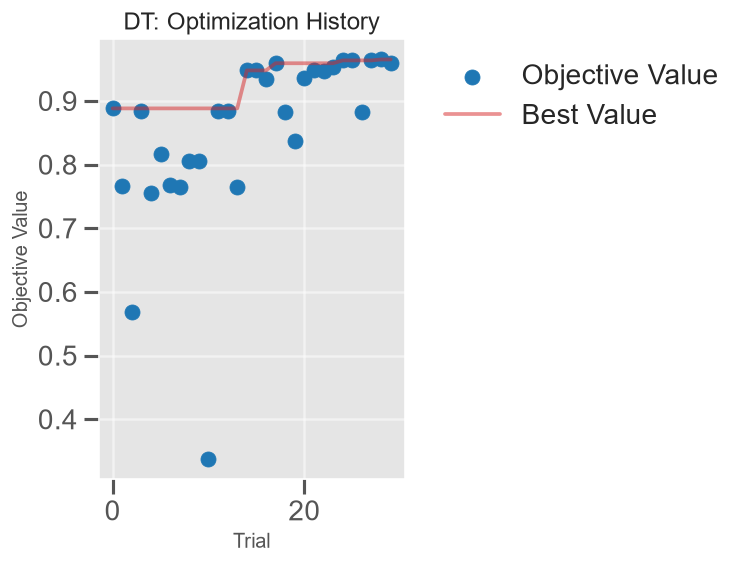

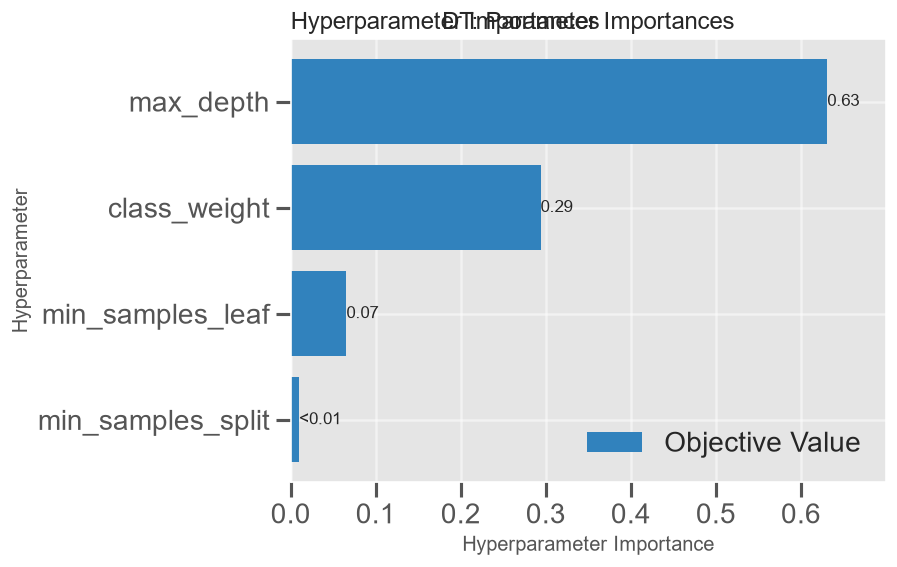

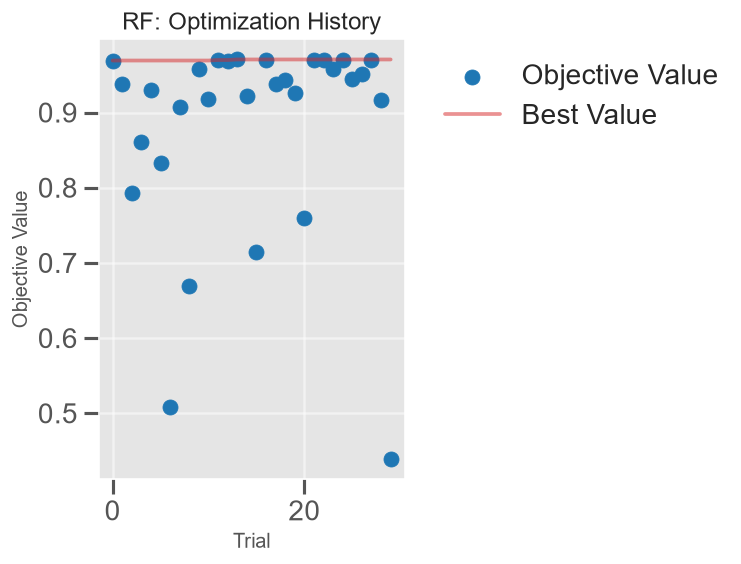

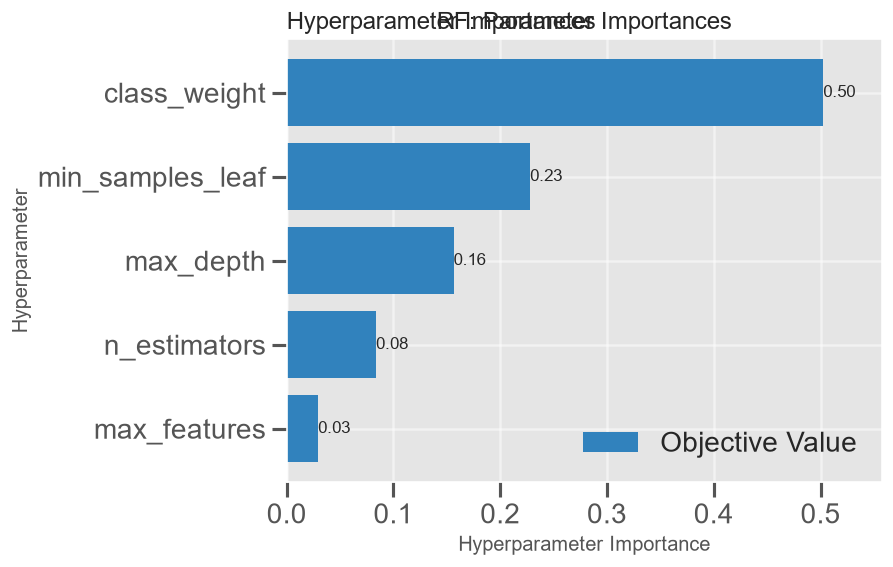

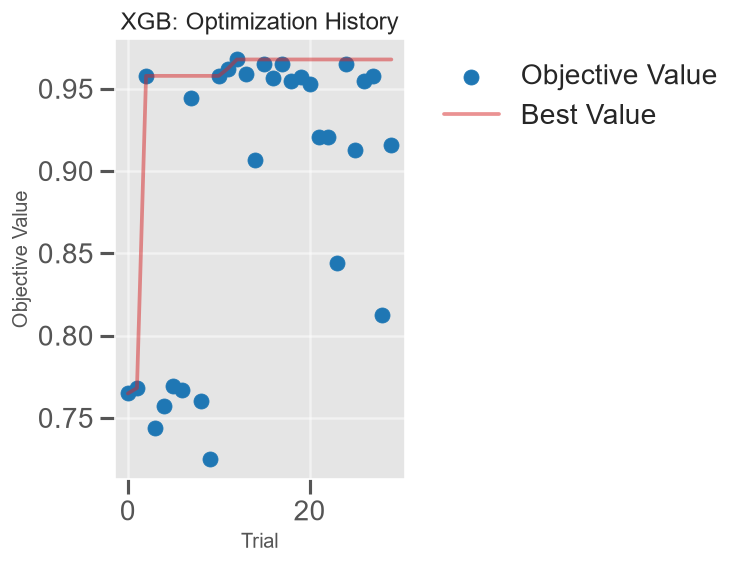

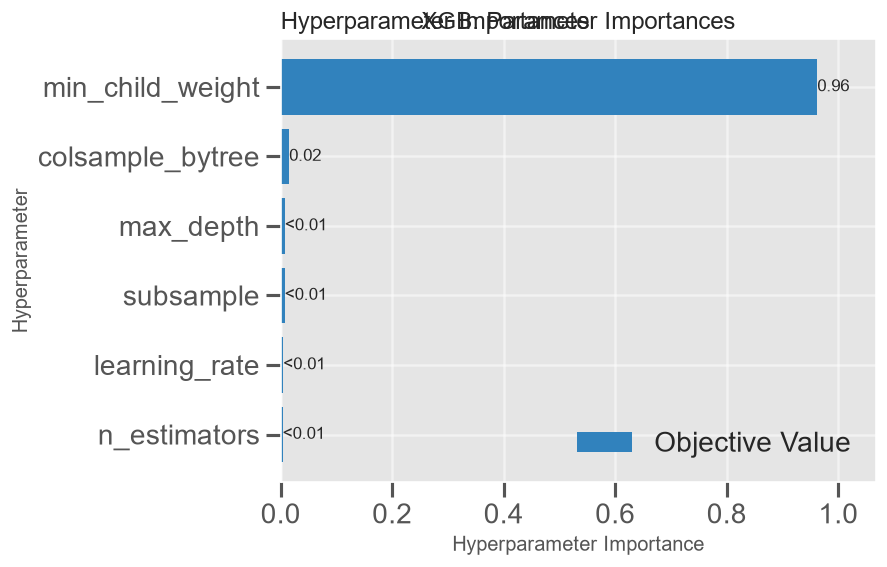

In [13]:
# Optuna diagnostic plots
import optuna.visualization.matplotlib as optuna_plt

for model_name in ["DT", "RF", "XGB"]:
    study = full_studies[model_name]
    optuna_plt.plot_optimization_history(study)
    plt.title(f"{model_name}: Optimization History")
    plt.show()

    optuna_plt.plot_param_importances(study)
    plt.title(f"{model_name}: Parameter Importances")
    plt.show()

## Step 5: Statistical Comparison via Nadeau-Bengio Corrected t-Test (Section 3.5)

The paired repeated-CV differences are assessed with a corrected resampled t-test. This is more conservative than a naive paired t-test because repeated CV folds overlap and therefore violate the independence assumption of simple paired tests.

In [30]:
def nadeau_bengio_t_test(differences, k=5, r=3, n_test=0.2, n_train=0.8):
    d = np.asarray(differences, dtype=float)
    mean_diff = d.mean()
    sd_diff = d.std(ddof=1)
    correction = (1.0 / (k * r)) + (n_test / n_train)
    t_stat = mean_diff / np.sqrt(correction * (sd_diff ** 2))
    df = k * r - 1
    p_value = stats.t.sf(abs(t_stat), df=df) * 2.0
    return mean_diff, sd_diff, t_stat, p_value

comparison_rows = []

# Variant A vs Variant B for each model
for model_name in ["DT", "RF", "XGB"]:
    diff = fold_store[("Variant B", model_name)]["f1_macro"] - fold_store[("Variant A", model_name)]["f1_macro"]
    mean_d, sd_d, t_stat, p_val = nadeau_bengio_t_test(diff)
    comparison_rows.append({
        "Comparison Pair": f"{model_name}: Variant A vs Variant B",
        "Mean Difference (d̄)": mean_d,
        "Std Dev (σ̂_d)": sd_d,
        "t-statistic": t_stat,
        "p-value": p_val,
        "Significant (p < 0.05)?": p_val < 0.05,
    })

# Compare top two Variant B models
variant_b_means = {m: np.mean(fold_store[("Variant B", m)]["f1_macro"]) for m in ["DT", "RF", "XGB"]}
ordered = sorted(variant_b_means.items(), key=lambda kv: kv[1], reverse=True)
first_model, second_model = ordered[0][0], ordered[1][0]
paired_diff = fold_store[("Variant B", first_model)]["f1_macro"] - fold_store[("Variant B", second_model)]["f1_macro"]
mean_d, sd_d, t_stat, p_val = nadeau_bengio_t_test(paired_diff)
comparison_rows.append({
    "Comparison Pair": f"{first_model} vs {second_model} (Variant B)",
    "Mean Difference (d̄)": mean_d,
    "Std Dev (σ̂_d)": sd_d,
    "t-statistic": t_stat,
    "p-value": p_val,
    "Significant (p < 0.05)?": p_val < 0.05,
})

Table_5 = pd.DataFrame(comparison_rows)
print("\nTable 5:\n", Table_5.round({
    "Mean Difference (d̄)": 6,
    "Std Dev (σ̂_d)": 6,
    "t-statistic": 6,
    "p-value": 6,
}))


Table 5:
                Comparison Pair  Mean Difference (d̄)  Std Dev (σ̂_d)  \
0   DT: Variant A vs Variant B              0.063184        0.051152   
1   RF: Variant A vs Variant B              0.061023        0.020999   
2  XGB: Variant A vs Variant B              0.053089        0.025602   
3        RF vs XGB (Variant B)              0.002819        0.003575   

   t-statistic   p-value  Significant (p < 0.05)?  
0     2.195045  0.045521                     True  
1     5.164027  0.000144                     True  
2     3.684852  0.002450                     True  
3     1.401279  0.182908                    False  


### Interpretation checkpoint — statistical tests

For each row in Table 5, `Mean Difference` is the paired score difference in the displayed order. A p-value below 0.05 is evidence of a difference under the corrected resampling approximation; a larger p-value means the experiment does not establish a difference, not that the models are equivalent. Because the correction is approximate, report effect size and uncertainty as well as significance.

## Step 6: Final Holdout Test Evaluation (Section 3.6)

All tuned Variant B models are evaluated on the untouched holdout split. The model with the best macro-F1 score is selected for the final classification report and confusion matrix analysis.


DT holdout metrics:
  Accuracy = 0.9722
  Macro F1 = 0.7817
  Balanced Accuracy = 0.7871

RF holdout metrics:
  Accuracy = 0.9944
  Macro F1 = 0.9941
  Balanced Accuracy = 0.9900

XGB holdout metrics:
  Accuracy = 0.9722
  Macro F1 = 0.7817
  Balanced Accuracy = 0.7871

Table 6:
   Model  Accuracy  Macro F1  Balanced Accuracy
0    DT    0.9722    0.7817             0.7871
1    RF    0.9944    0.9941             0.9900
2   XGB    0.9722    0.7817             0.7871

Model selected by nested-CV macro-F1 (holdout remains untouched for selection): XGB

Classification report:

              precision    recall  f1-score   support

           1     0.0000    0.0000    0.0000         2
           2     0.9048    0.9500    0.9268        20
           3     0.9783    0.9854    0.9818       137
           5     1.0000    1.0000    1.0000        13
           U     1.0000    1.0000    1.0000         8

    accuracy                         0.9722       180
   macro avg     0.7766    0.7871    0.7

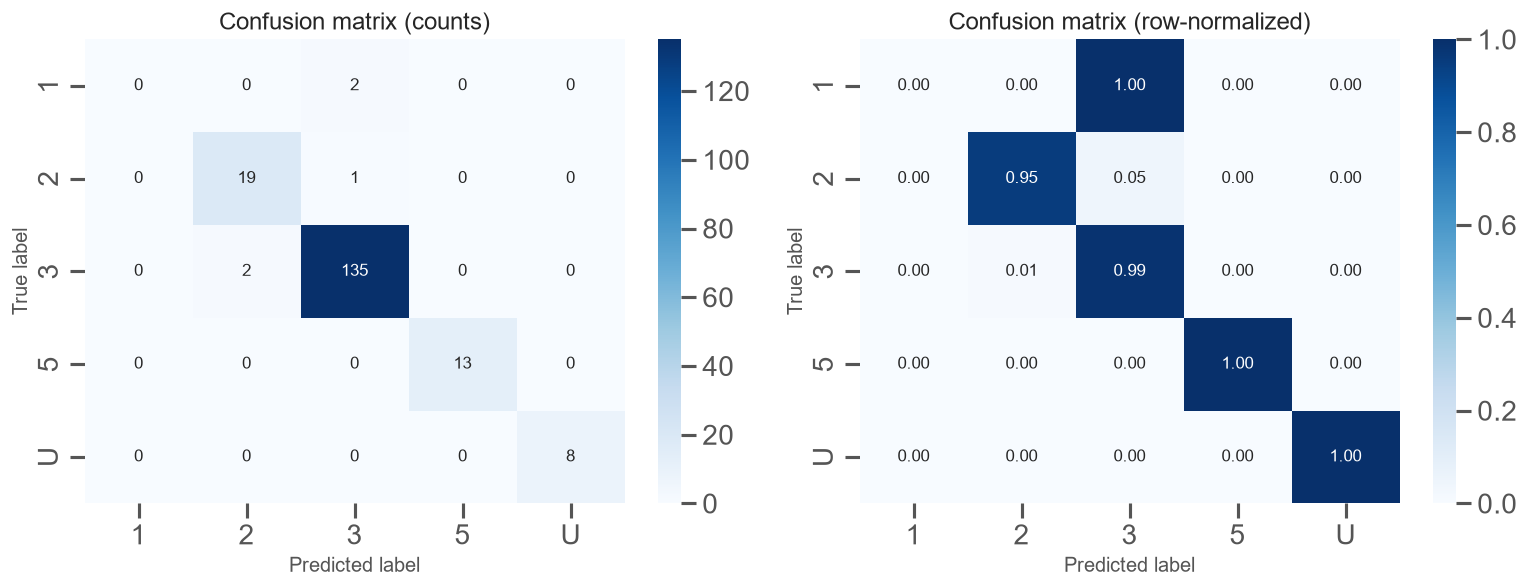

In [15]:
holdout_rows = []
for model_name, pipeline in final_models.items():
    y_pred = pipeline.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average="macro")
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    holdout_rows.append({
        "Model": model_name,
        "Accuracy": acc,
        "Macro F1": macro_f1,
        "Balanced Accuracy": bal_acc,
    })
    print(f"\n{model_name} holdout metrics:")
    print(f"  Accuracy = {acc:.4f}")
    print(f"  Macro F1 = {macro_f1:.4f}")
    print(f"  Balanced Accuracy = {bal_acc:.4f}")

Table_6 = pd.DataFrame(holdout_rows)
print("\nTable 6:\n", Table_6.round(4))

# Select the model using nested-CV results, not the holdout scores. This preserves
# the holdout set as a final evaluation rather than a model-selection set.
best_model_name = max(nested_scores, key=lambda name: float(np.mean(nested_scores[name])))
best_model = final_models[best_model_name]
print("\nModel selected by nested-CV macro-F1 (holdout remains untouched for selection):", best_model_name)

y_best_pred = best_model.predict(X_test)
print("\nClassification report:\n")
print(classification_report(
    y_test,
    y_best_pred,
    target_names=[str(lbl) for lbl in label_encoder.classes_],
    digits=4,
))

labels = np.arange(len(label_encoder.classes_))
cm = confusion_matrix(y_test, y_best_pred, labels=labels)
cm_row_norm = cm.astype(float) / np.clip(cm.sum(axis=1, keepdims=True), 1, None)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=[str(lbl) for lbl in label_encoder.classes_], yticklabels=[str(lbl) for lbl in label_encoder.classes_], ax=axes[0])
axes[0].set_title("Confusion matrix (counts)")
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("True label")

sns.heatmap(cm_row_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=[str(lbl) for lbl in label_encoder.classes_], yticklabels=[str(lbl) for lbl in label_encoder.classes_], ax=axes[1])
axes[1].set_title("Confusion matrix (row-normalized)")
axes[1].set_xlabel("Predicted label")
axes[1].set_ylabel("True label")
plt.tight_layout()
plt.show()

### Holdout vs. CV discrepancy

A holdout set is a finite sample, and this is especially important when some classes are sparse. In multiclass classification, a single sample from a rare class can change macro-F1 noticeably. Therefore, small differences between repeated-CV estimates and final holdout metrics are expected and are not necessarily signs of model instability.

## Step 7: Feature Importance Diagnostics (Section 3.7)

The next analysis compares top-15 features using impurity-based importance and permutation importance. In the context of missing-data modelling, we also inspect whether the missingness indicators appear among the most important features, which is a strong diagnostic sign that missingness itself carries predictive signal.

### Interpretation checkpoint — test metrics

Compare macro-F1 and balanced accuracy with accuracy rather than choosing by accuracy alone. A lower macro-F1 alongside high accuracy indicates that minority classes are being missed. The row-normalized confusion matrix makes per-class recall visible; rows with small support should be interpreted cautiously because one error can change their recall substantially.


Top-15 MDI features for DT:
                                       feature  importance
0                         base__num__hardness    0.230216
1            missing__missingindicator_family    0.224952
2       missing__missingindicator_formability    0.204553
3   missing__missingindicator_surface-quality    0.180686
4                            base__num__thick    0.063814
5                           base__num__carbon    0.038237
6                         base__num__strength    0.033021
7             missing__missingindicator_steel    0.024333
8                            base__num__width    0.000094
9                              base__num__len    0.000094
10                       base__cat__family_TN    0.000000
11                         base__cat__steel_R    0.000000
12                         base__cat__steel_S    0.000000
13                         base__cat__steel_V    0.000000
14                         base__cat__steel_W    0.000000
Missing indicator columns in top-15 MDI fo

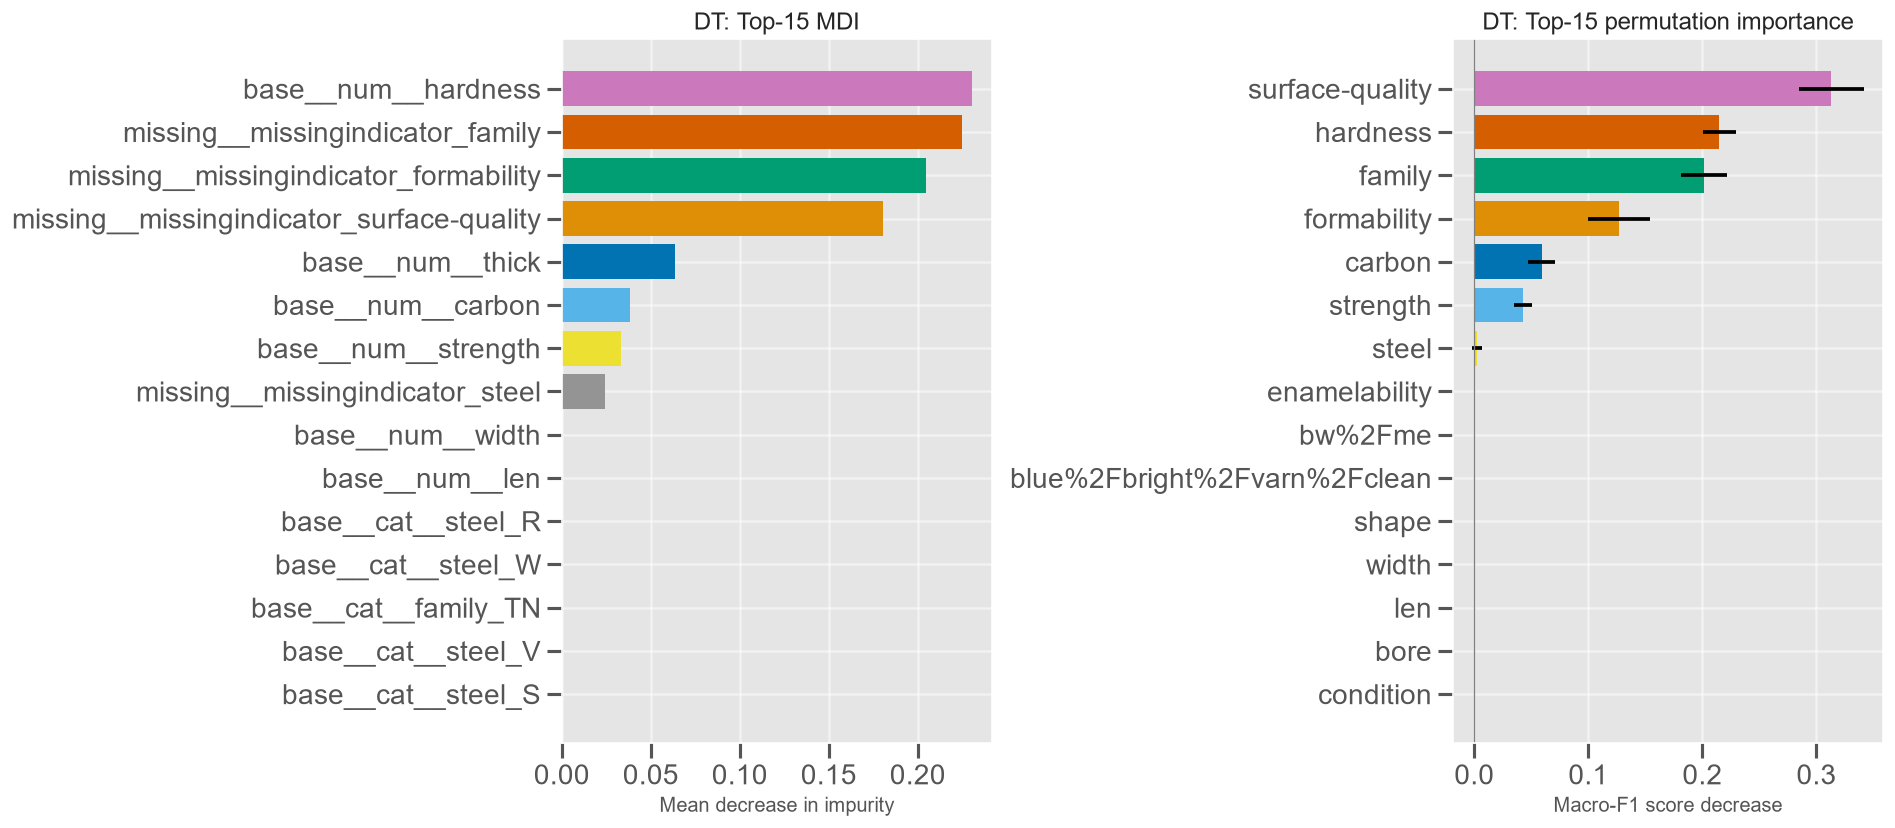


Top-15 MDI features for RF:
                                       feature  importance
0   missing__missingindicator_surface-quality    0.143280
1                         base__num__hardness    0.109160
2            missing__missingindicator_family    0.076045
3       missing__missingindicator_formability    0.066133
4                          base__cat__steel_A    0.064001
5         missing__missingindicator_condition    0.061951
6                            base__num__thick    0.060366
7                         base__num__strength    0.054657
8                    base__cat__formability_2    0.052155
9                          base__cat__steel_R    0.032967
10                           base__num__width    0.025740
11               base__cat__surface-quality_E    0.024200
12                          base__num__carbon    0.022113
13                   base__cat__formability_3    0.019795
14                      base__cat__shape_COIL    0.019420
Missing indicator columns in top-15 MDI fo

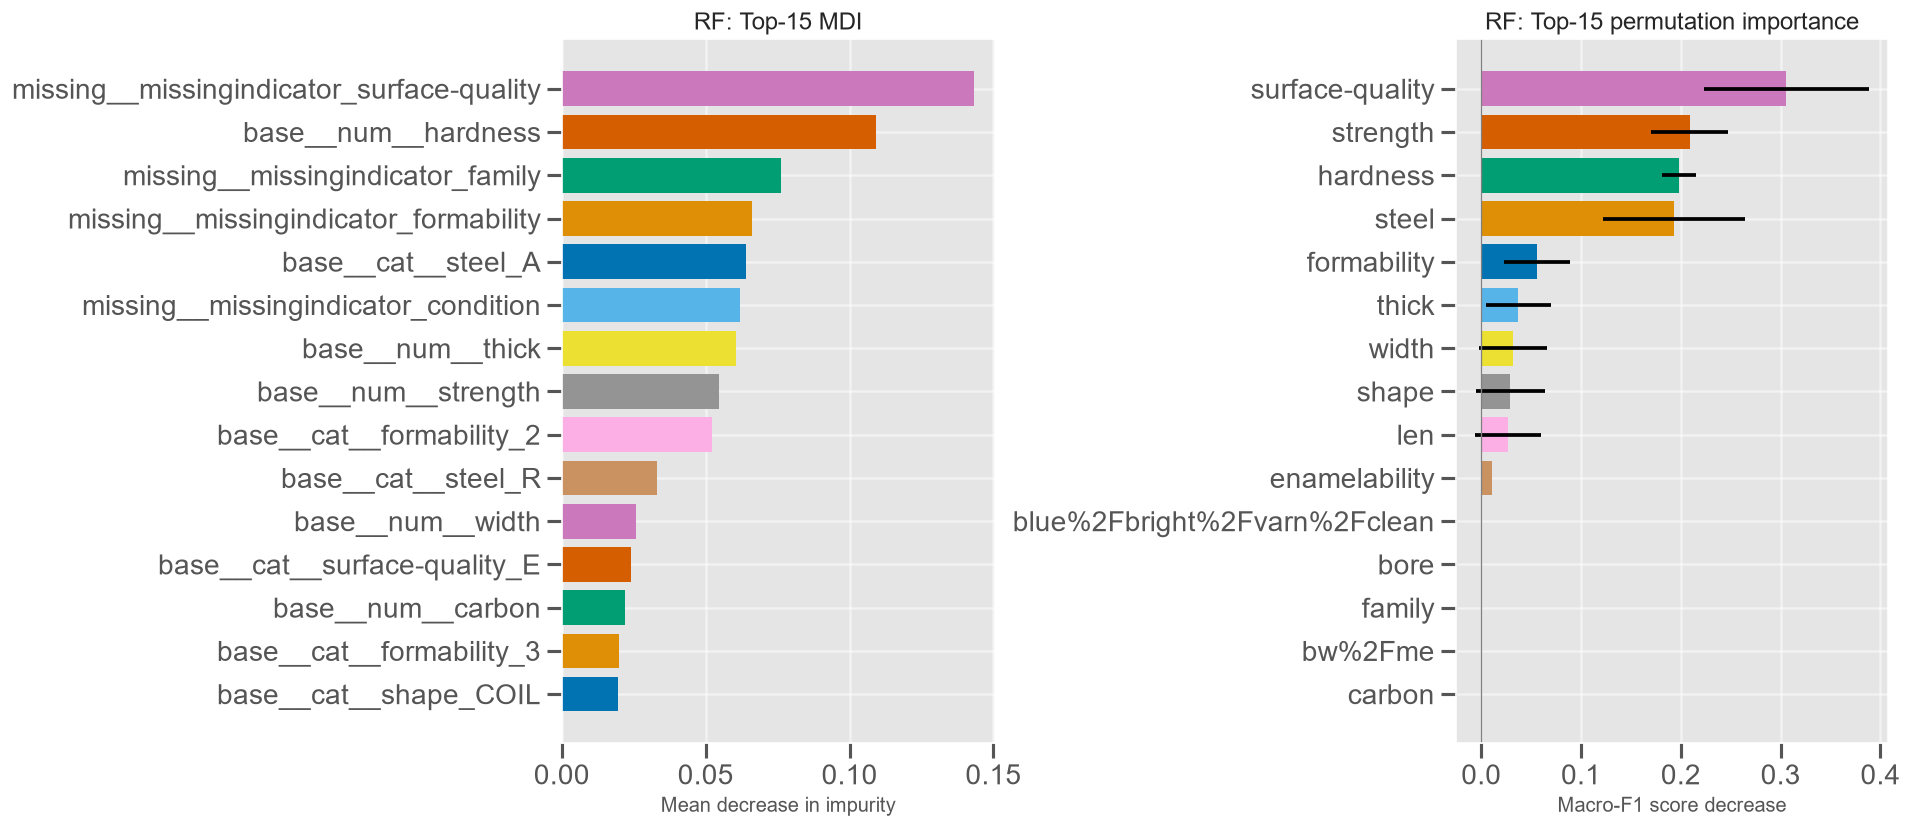


Top-15 MDI features for XGB:
                                               feature  importance
0                                base__cat__family_ZS    0.236794
1                    missing__missingindicator_family    0.109567
2                                  base__cat__steel_K    0.078921
3                            base__cat__formability_1    0.074900
4                                base__cat__family_TN    0.063097
5                          base__cat__enamelability_2    0.041690
6           missing__missingindicator_surface-quality    0.037264
7                            base__cat__formability_3    0.033973
8                                 base__num__hardness    0.027980
9                              base__cat__condition_A    0.026205
10              missing__missingindicator_formability    0.024133
11  missing__missingindicator_blue%2Fbright%2Fvarn...    0.023345
12                                 base__cat__steel_S    0.021902
13                         base__cat__enamela

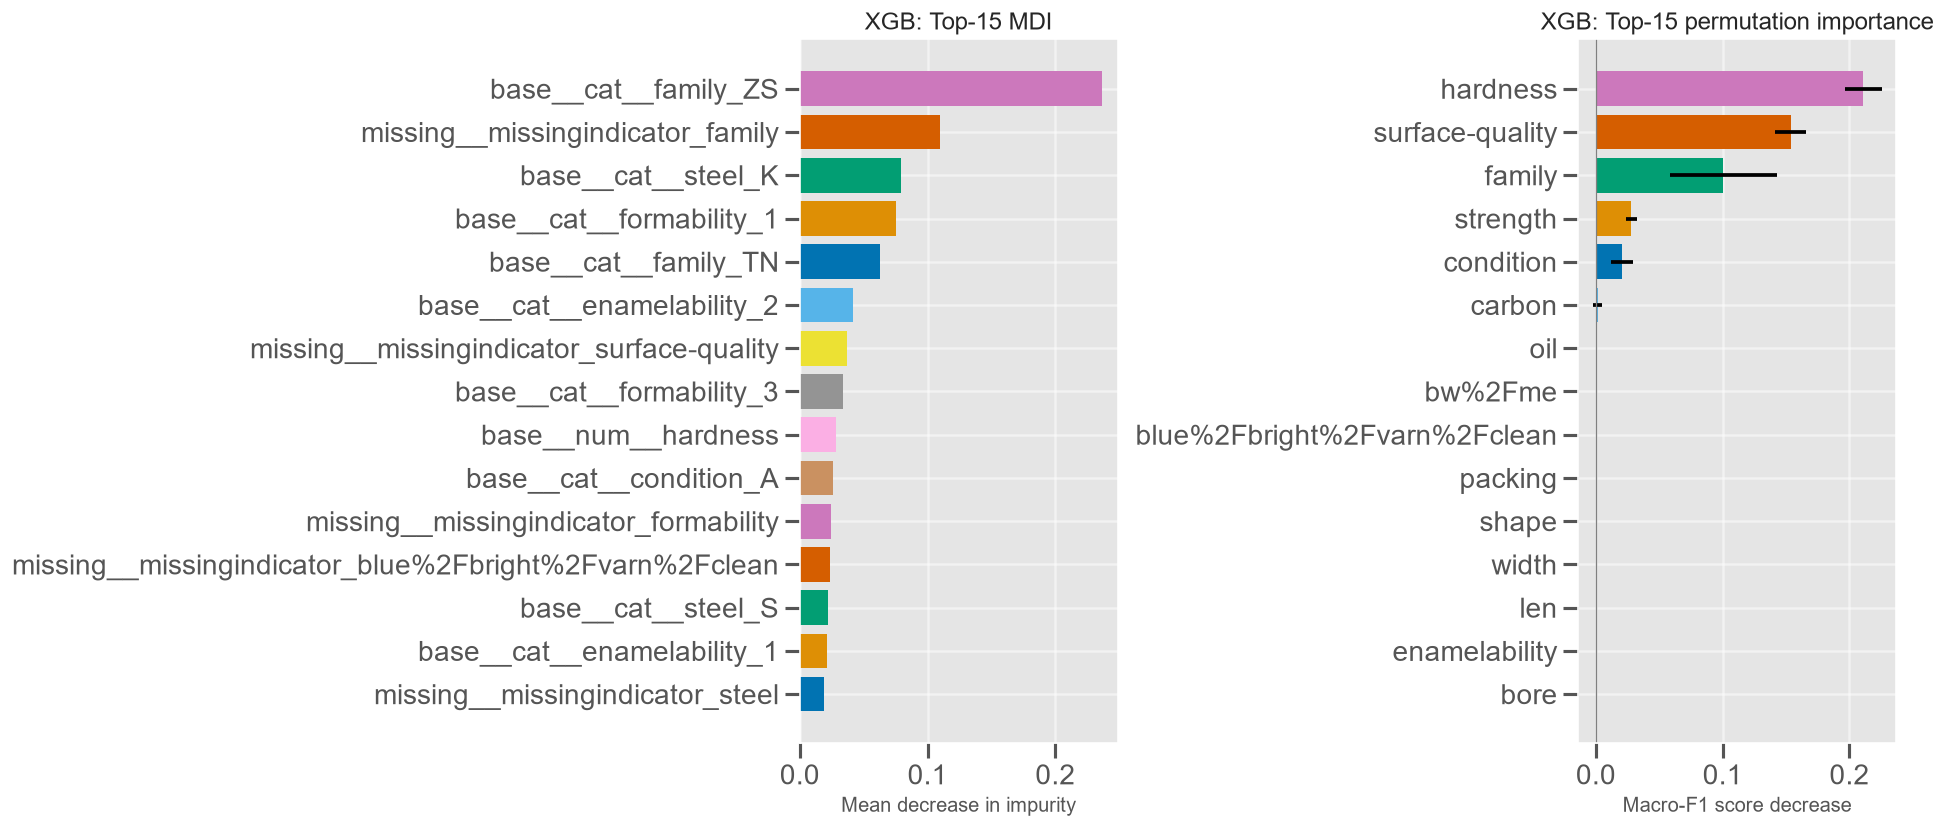

In [16]:
def get_top_mdi(pipeline, top_n=15):
    preprocessor = pipeline.named_steps["preprocess"]
    model = pipeline.named_steps["model"]
    if not hasattr(model, "feature_importances_"):
        return pd.DataFrame(columns=["feature", "importance"])
    feature_names = preprocessor.get_feature_names_out()
    importances = model.feature_importances_
    df = pd.DataFrame({"feature": feature_names, "importance": importances})
    return df.sort_values("importance", ascending=False).head(top_n).reset_index(drop=True)

for model_name, pipeline in final_models.items():
    mdi_df = get_top_mdi(pipeline, top_n=15)
    print(f"\nTop-15 MDI features for {model_name}:\n", mdi_df)
    missing_in_top_mdi = mdi_df[mdi_df["feature"].str.contains("missing", case=False)]
    print(f"Missing indicator columns in top-15 MDI for {model_name}:\n", missing_in_top_mdi)

    perm = permutation_importance(
        pipeline,
        X_test,
        y_test,
        scoring="f1_macro",
        n_repeats=10,
        random_state=SEED,
        n_jobs=1,
    )
    feature_names = X_test.columns.to_numpy()
    if len(feature_names) != len(perm.importances_mean):
        raise RuntimeError("Permutation importance output does not match the original input columns.")
    perm_df = pd.DataFrame({
        "feature": feature_names,
        "importance_mean": perm.importances_mean,
        "importance_std": perm.importances_std,
    }).sort_values("importance_mean", ascending=False).head(15).reset_index(drop=True)
    print(f"\nTop-15 permutation importance features for {model_name}:\n", perm_df)
    missing_source_features = X.columns[X.isna().any()]
    missing_in_top_perm = perm_df[perm_df["feature"].isin(missing_source_features)]
    print(f"Missing-data source features in top-15 permutation importance for {model_name}:\n", missing_in_top_perm)

    mdi_plot = mdi_df.sort_values("importance", ascending=True)
    perm_plot = perm_df.sort_values("importance_mean", ascending=True)
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].barh(mdi_plot["feature"], mdi_plot["importance"], color=sns.color_palette("colorblind", n_colors=len(mdi_plot)))
    axes[0].set_title(f"{model_name}: Top-15 MDI")
    axes[0].set_xlabel("Mean decrease in impurity")
    axes[1].barh(perm_plot["feature"], perm_plot["importance_mean"], xerr=perm_plot["importance_std"], color=sns.color_palette("colorblind", n_colors=len(perm_plot)))
    axes[1].axvline(0, color="gray", linewidth=0.8)
    axes[1].set_title(f"{model_name}: Top-15 permutation importance")
    axes[1].set_xlabel("Macro-F1 score decrease")
    fig.tight_layout()
    plt.show()

### Interpretation of missing-indicator importance

If the indicator columns created by `MissingIndicator` appear in the top-ranked features, this is a strong sign that missingness is not random and contains exploitable predictive structure. This is consistent with the earlier chi-square tests: when the missingness pattern is related to the target class, the indicators can improve the model by encoding systematic missingness as a signal rather than merely replacing missing values with a central statistic.

### Interpretation checkpoint — importance measures

Read each model's two top-15 tables together. MDI is an in-sample split-impurity measure on the transformed one-hot/indicator features; permutation importance measures the holdout macro-F1 drop after shuffling each original input column. They are not directly on the same scale. High-cardinality variables can be favored by MDI because they offer more candidate split points; correlated features can dilute permutation importance because one feature can substitute for another. Missingness indicators in top-15 support the hypothesis that the missingness pattern is predictive, but do not alone establish MAR or MNAR.

## Step 8: Prediction Discrepancy & SHAP Attribution (Section 3.8)

We identify cases where the three tuned models disagree and inspect one representative conflicting example in detail, including the raw feature values, imputation replacements, and Shapley explanations.

Test samples with disagreement among models: 4 / 180

Table 7 — disagreement cases:
 Source Sample ID True Class DT Pred RF Pred XGB Pred
  Test       746          3       2       3        2
  Test       288          1       3       1        3
  Test       827          3       2       3        2
  Test       406          1       3       1        3

Detailed case source: test
Original sample values (NaN means missing before imputation):


,Original value
family,NaN
steel,V
carbon,0
hardness,0
condition,S
formability,2
strength,0
surface-quality,NaN
enamelability,1
bw%2Fme,NaN


True class: 3
Model predictions: {'DT': '2', 'RF': '3', 'XGB': '2'}

Missing values and fitted replacement values:


,Feature,Original value,Imputed value (illustrative)
0,family,NaN,TN
1,surface-quality,NaN,E
2,bw%2Fme,NaN,B
3,blue%2Fbright%2Fvarn%2Fclean,NaN,B
4,oil,NaN,Y
5,packing,NaN,3



DT: top-5 SHAP contributions for its predicted class 2:


,Feature,SHAP value,Absolute SHAP
41,missing__missingindicator_family,0.352592,0.352592
44,missing__missingindicator_formability,0.228404,0.228404
45,missing__missingindicator_surface-quality,0.131212,0.131212
1,base__num__hardness,0.103565,0.103565
2,base__num__strength,-0.008182,0.008182


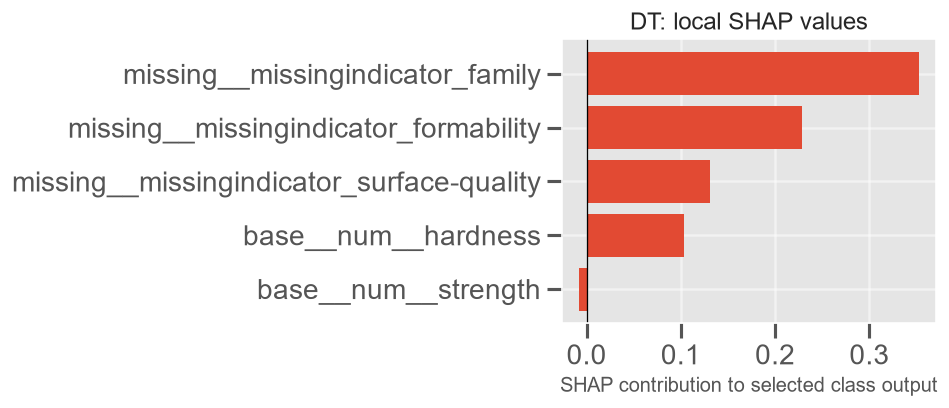


RF: top-5 SHAP contributions for its predicted class 3:


,Feature,SHAP value,Absolute SHAP
45,missing__missingindicator_surface-quality,-0.119015,0.119015
26,base__cat__enamelability_2,0.079920,0.079920
25,base__cat__enamelability_1,0.069567,0.069567
1,base__num__hardness,0.050032,0.050032
41,missing__missingindicator_family,0.043915,0.043915


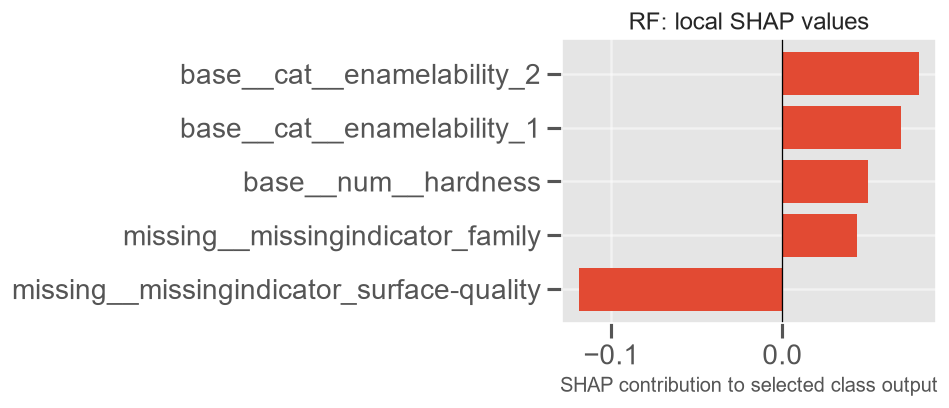


XGB: top-5 SHAP contributions for its predicted class 2:


,Feature,SHAP value,Absolute SHAP
45,missing__missingindicator_surface-quality,1.678691,1.678691
43,missing__missingindicator_condition,1.381879,1.381879
5,base__num__len,-0.695860,0.695860
8,base__cat__steel_A,0.608481,0.608481
11,base__cat__steel_R,-0.458291,0.458291


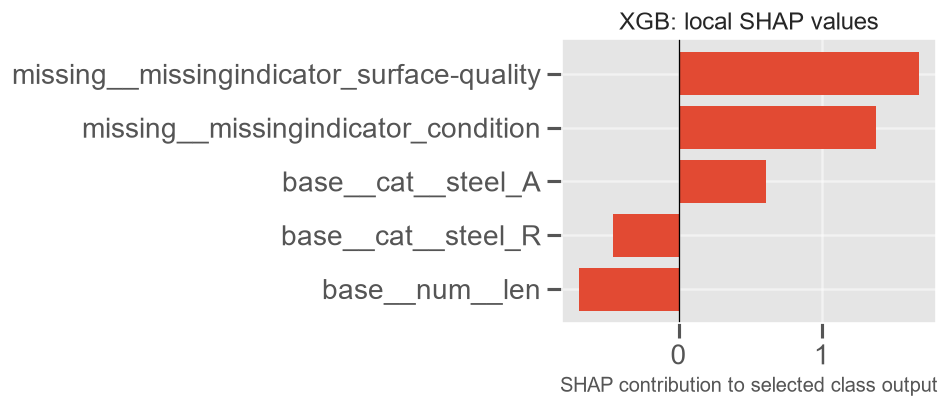


SHAP execution summary:


,Model,Status,Top features
0,DT,success,"missing__missingindicator_family, missing__mis..."
1,RF,success,"missing__missingindicator_surface-quality, bas..."
2,XGB,success,"missing__missingindicator_surface-quality, mis..."



Prediction confidence comparison (probabilities are model-specific):


,Model,Predicted class,Maximum class probability,Probability of its predicted class
0,DT,2,1.0000,1.0000
1,RF,3,0.5400,0.5400
2,XGB,2,0.8649,0.8649


In [17]:
# Prediction disagreement analysis. Never index test predictions with OOF training indices.
test_predictions = {name: pipeline.predict(X_test) for name, pipeline in final_models.items()}
test_pred_matrix = np.column_stack([test_predictions["DT"], test_predictions["RF"], test_predictions["XGB"]])
test_conflicts = np.flatnonzero(np.any(test_pred_matrix != test_pred_matrix[:, [0]], axis=1))
print(f"Test samples with disagreement among models: {len(test_conflicts)} / {len(X_test)}")

if len(test_conflicts) >= 3:
    source_kind = "test"
    conflict_rows = test_conflicts[:max(3, min(10, len(test_conflicts)))]
    Table_7 = pd.DataFrame([
        {
            "Source": "Test",
            "Sample ID": str(X_test.index[idx]),
            "True Class": str(label_encoder.inverse_transform([y_test[idx]])[0]),
            "DT Pred": str(label_encoder.inverse_transform([test_predictions["DT"][idx]])[0]),
            "RF Pred": str(label_encoder.inverse_transform([test_predictions["RF"][idx]])[0]),
            "XGB Pred": str(label_encoder.inverse_transform([test_predictions["XGB"][idx]])[0]),
        } for idx in conflict_rows
    ])
    chosen_pos = int(conflict_rows[0])
    raw_sample = X_test.iloc[[chosen_pos]].copy()
    true_encoded = int(y_test[chosen_pos])
    sample_predictions = {name: int(test_predictions[name][chosen_pos]) for name in final_models}
else:
    print("Fewer than three test disagreements: generating out-of-fold predictions on the training partition, as required.")
    oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    oof = {}
    for name in ["DT", "RF", "XGB"]:
        oof_pipe = build_pipeline(name, with_indicators=True, params=full_studies[name].best_trial.params)
        oof[name] = cross_val_predict(oof_pipe, X_train, y_train, cv=oof_cv, method="predict", n_jobs=1)
    oof_matrix = np.column_stack([oof["DT"], oof["RF"], oof["XGB"]])
    oof_conflicts = np.flatnonzero(np.any(oof_matrix != oof_matrix[:, [0]], axis=1))
    if len(oof_conflicts):
        source_kind = "OOF training"
        conflict_rows = oof_conflicts[:max(3, min(10, len(oof_conflicts)))]
        Table_7 = pd.DataFrame([
            {
                "Source": "OOF training",
                "Sample ID": str(X_train.index[idx]),
                "True Class": str(label_encoder.inverse_transform([y_train[idx]])[0]),
                "DT Pred": str(label_encoder.inverse_transform([oof["DT"][idx]])[0]),
                "RF Pred": str(label_encoder.inverse_transform([oof["RF"][idx]])[0]),
                "XGB Pred": str(label_encoder.inverse_transform([oof["XGB"][idx]])[0]),
            } for idx in conflict_rows
        ])
        chosen_pos = int(conflict_rows[0])
        raw_sample = X_train.iloc[[chosen_pos]].copy()
        true_encoded = int(y_train[chosen_pos])
        sample_predictions = {name: int(oof[name][chosen_pos]) for name in ["DT", "RF", "XGB"]}
    else:
        # A degenerate all-agree case should not crash the notebook; report it explicitly.
        source_kind = "none"
        Table_7 = pd.DataFrame(columns=["Source", "Sample ID", "True Class", "DT Pred", "RF Pred", "XGB Pred"])
        raw_sample = None
        print("No disagreements were found in test or OOF predictions; SHAP case study is skipped.")

print("\nTable 7 — disagreement cases:\n", Table_7.to_string(index=False))

if raw_sample is not None:
    print(f"\nDetailed case source: {source_kind}")
    print("Original sample values (NaN means missing before imputation):")
    display(raw_sample.T.rename(columns={raw_sample.index[0]: "Original value"}))
    print("True class:", label_encoder.inverse_transform([true_encoded])[0])
    print("Model predictions:", {k: label_encoder.inverse_transform([v])[0] for k, v in sample_predictions.items()})

    # Show the fitted imputation value for each missing field using the selected final pipeline.
    # For OOF cases, final pipelines are used only to illustrate learned replacement values;
    # OOF predictions themselves were produced without fitting on their own row.
    inspect_pipeline = final_models[best_model_name]
    inspect_preprocessor = inspect_pipeline.named_steps["preprocess"]
    missing_cols = raw_sample.columns[raw_sample.isna().any()].tolist()
    if missing_cols:
        base = inspect_preprocessor.transformer_list[0][1]
        num_cols = list(base.transformers_[0][2])
        cat_cols = list(base.transformers_[1][2])
        num_imputer = base.named_transformers_["num"].named_steps["imputer"]
        cat_imputer = base.named_transformers_["cat"].named_steps["imputer"]
        replacements = []
        for col in missing_cols:
            if col in num_cols:
                value = num_imputer.statistics_[num_cols.index(col)]
            elif col in cat_cols:
                value = cat_imputer.statistics_[cat_cols.index(col)]
            else:
                value = "not available"
            replacements.append({"Feature": col, "Original value": np.nan, "Imputed value (illustrative)": value})
        print("\nMissing values and fitted replacement values:")
        display(pd.DataFrame(replacements))
    else:
        print("This case has no missing feature values; disagreement is due to model boundaries/learned interactions rather than imputation of this row.")

    # Explain the predicted class separately for each model. SHAP API output differs by
    # library version; normalize common list/2-D/3-D forms and report any model-specific issue.
    shap_summary_rows = []
    for model_name, pipeline in final_models.items():
        try:
            transformed = pipeline.named_steps["preprocess"].transform(raw_sample)
            model = pipeline.named_steps["model"]
            explainer = shap.TreeExplainer(model)
            sv = explainer.shap_values(transformed)
            pred_class = int(pipeline.predict(raw_sample)[0])
            if isinstance(sv, list):
                arr = np.asarray(sv, dtype=object) if len(sv) == 0 else None
                if len(sv) > pred_class:
                    vals = np.asarray(sv[pred_class])[0]
                else:
                    vals = np.asarray(sv[0])[0]
            else:
                arr = np.asarray(sv)
                if arr.ndim == 3:
                    # SHAP versions may return (samples, features, classes) or (classes, samples, features).
                    if arr.shape[0] == 1 and arr.shape[1] == transformed.shape[1]:
                        vals = arr[0, :, pred_class]
                    elif arr.shape[-1] == transformed.shape[1]:
                        vals = arr[pred_class, 0, :]
                    else:
                        vals = arr[0, :, min(pred_class, arr.shape[2]-1)]
                elif arr.ndim == 2:
                    vals = arr[0]
                else:
                    raise ValueError(f"Unexpected SHAP array shape: {arr.shape}")
            names = pipeline.named_steps["preprocess"].get_feature_names_out()
            if len(vals) != len(names):
                raise ValueError(f"SHAP features ({len(vals)}) != transformed feature names ({len(names)}).")
            top = pd.DataFrame({"Feature": names, "SHAP value": vals, "Absolute SHAP": np.abs(vals)})
            top = top.sort_values("Absolute SHAP", ascending=False).head(5)
            print(f"\n{model_name}: top-5 SHAP contributions for its predicted class "
                  f"{label_encoder.inverse_transform([pred_class])[0]}:")
            display(top)
            shap_summary_rows.append({"Model": model_name, "Status": "success", "Top features": ", ".join(top["Feature"].astype(str).tolist())})
            plot_df = top.sort_values("SHAP value")
            plt.figure(figsize=(8, 3.5))
            plt.barh(plot_df["Feature"], plot_df["SHAP value"])
            plt.axvline(0, color="black", linewidth=0.8)
            plt.title(f"{model_name}: local SHAP values")
            plt.xlabel("SHAP contribution to selected class output")
            plt.tight_layout()
            plt.show()
        except Exception as exc:
            print(f"\nSHAP could not be computed for {model_name} in this library/model combination: {type(exc).__name__}: {exc}")
            shap_summary_rows.append({"Model": model_name, "Status": f"failed: {type(exc).__name__}", "Top features": ""})

    print("\nSHAP execution summary:")
    display(pd.DataFrame(shap_summary_rows))

    probability_rows = []
    for model_name, pipeline in final_models.items():
        probs = pipeline.predict_proba(raw_sample)[0]
        probability_rows.append({
            "Model": model_name,
            "Predicted class": str(label_encoder.inverse_transform([int(pipeline.predict(raw_sample)[0])])[0]),
            "Maximum class probability": float(np.max(probs)),
            "Probability of its predicted class": float(probs[int(pipeline.predict(raw_sample)[0])]),
        })
    print("\nPrediction confidence comparison (probabilities are model-specific):")
    display(pd.DataFrame(probability_rows).round(4))


### Interpretation checkpoint — disagreement and SHAP

Use Table 7 to identify which algorithms disagree and on which classes. In the SHAP tables, positive/negative contributions are interpreted relative to the explained class output (the exact output scale depends on the model and SHAP configuration). Compare top features across DT, RF, and XGBoost rather than expecting identical explanations: a single tree uses one path, while ensembles aggregate many trees. If SHAP fails for a library-version-specific API, the cell records the exception and continues, so the rest of the notebook still runs.

## Step 9: Final Synthesis Conclusion

The conclusion below is generated from this run's tables rather than assuming that a particular algorithm or preprocessing variant must win. Interpret macro-F1 as the primary metric because it weights classes equally, and use the corrected paired test—not a tiny difference between means—to discuss statistical evidence. The holdout set is used only for the final comparison and must not be used to revise the tuning process. Rare classes excluded under the documented policy are outside the scope of the fitted classifiers; their omission must be acknowledged in the report.



In [18]:
# Data-driven 8–12 sentence conclusion based on this run's actual results.
baseline_b = {m: float(np.mean(fold_store[("Variant B", m)]["f1_macro"])) for m in ["DT", "RF", "XGB"]}
best_base = max(baseline_b, key=baseline_b.get)
best_nested = max(nested_scores, key=lambda m: float(np.mean(nested_scores[m])))
nested_best_mean = float(np.mean(nested_scores[best_nested]))
nested_best_std = float(np.std(nested_scores[best_nested], ddof=1)) if len(nested_scores[best_nested]) > 1 else 0.0
best_holdout_row = Table_6.loc[Table_6["Model"] == best_nested].iloc[0]
sig_best_pair = Table_5.iloc[-1]
variant_effects = {
    m: float(np.mean(fold_store[("Variant B", m)]["f1_macro"]) - np.mean(fold_store[("Variant A", m)]["f1_macro"]))
    for m in ["DT", "RF", "XGB"]
}
best_variant_effect = max(variant_effects.items(), key=lambda kv: kv[1])
tuning_effects = {
    m: float(np.mean(nested_scores[m]) - np.mean(fold_store[("Variant B", m)]["f1_macro"]))
    for m in ["DT", "RF", "XGB"]
}
largest_tuning_gain = max(tuning_effects.items(), key=lambda kv: kv[1])
best_study = full_studies[best_nested]
bias_gap = float(best_study.best_value - nested_best_mean)
rare_text = f"{len(rare_classes)} class(es) with fewer than six examples were excluded from modelling" if rare_classes else "no class needed exclusion under the fewer-than-six policy"
print("RUN-SPECIFIC CONCLUSION (10 sentences)")
print(f"1. Among Variant B baseline models, {best_base} had the highest repeated-CV mean macro-F1 ({baseline_b[best_base]:.4f}); its fold standard deviation is {np.std(fold_store[('Variant B', best_base)]['f1_macro'], ddof=1):.4f}.")
print(f"2. The model selected by nested-CV performance is {best_nested}, with nested macro-F1 {nested_best_mean:.4f} ± {nested_best_std:.4f}; this standard deviation indicates the observed outer-fold variability.")
print(f"3. On the untouched holdout set, {best_nested} achieved accuracy {best_holdout_row['Accuracy']:.4f}, macro-F1 {best_holdout_row['Macro F1']:.4f}, and balanced accuracy {best_holdout_row['Balanced Accuracy']:.4f}.")
print(f"4. The corrected test for the two strongest Variant B baseline models returned p={float(sig_best_pair['p-value']):.4g}; at alpha=0.05, the result is {'statistically significant' if float(sig_best_pair['p-value']) < 0.05 else 'not statistically significant'}.")
print(f"5. The largest mean macro-F1 change from adding missing indicators was for {best_variant_effect[0]} (Variant B minus A = {best_variant_effect[1]:+.4f}); this is an empirical result, not a guarantee that indicators help every model.")
print(f"6. For {best_nested}, the full-training-set Optuna best_value was {best_study.best_value:.4f}, while nested CV averaged {nested_best_mean:.4f}, a difference of {bias_gap:+.4f}; this gap illustrates the possible optimism of selecting the best inner-CV trial.")
print(f"7. Comparing nested-CV macro-F1 with baseline Variant B macro-F1, the largest observed change was for {largest_tuning_gain[0]} ({largest_tuning_gain[1]:+.4f}); this comparison is descriptive because the evaluation protocols differ.")
print("8. The confusion matrix and per-class classification report identify which retained classes are most difficult; classes with low support have especially unstable recall and can strongly affect macro-F1.")
print("9. The disagreement table and local SHAP explanations show whether competing models rely on similar transformed features or make different local decisions; probability margins help assess whether a case lies near a model's decision boundary.")
print(f"10. Scope limitation: {rare_text}; therefore, no conclusion should be extended to those excluded classes without a separate data-collection or modelling strategy.")


RUN-SPECIFIC CONCLUSION (10 sentences)
1. Among Variant B baseline models, RF had the highest repeated-CV mean macro-F1 (0.9505); its fold standard deviation is 0.0793.
2. The model selected by nested-CV performance is XGB, with nested macro-F1 0.9472 ± 0.0876; this standard deviation indicates the observed outer-fold variability.
3. On the untouched holdout set, XGB achieved accuracy 0.9722, macro-F1 0.7817, and balanced accuracy 0.7871.
4. The corrected test for the two strongest Variant B baseline models returned p=0.1829; at alpha=0.05, the result is not statistically significant.
5. The largest mean macro-F1 change from adding missing indicators was for DT (Variant B minus A = +0.0632); this is an empirical result, not a guarantee that indicators help every model.
6. For XGB, the full-training-set Optuna best_value was 0.9678, while nested CV averaged 0.9472, a difference of +0.0206; this gap illustrates the possible optimism of selecting the best inner-CV trial.
7. Comparing nest

## Step 10: Theoretical Mastery & Control Questions

### 1. Bias-Variance Decomposition: CART vs. Random Forest

A single CART is a high-variance learner because small changes in the data can alter split points and leaf assignments. The total error can be decomposed into irreducible noise, squared bias, and variance. Random forests reduce variance by aggregating a large number of decorrelated trees trained on bootstrap samples. The variance of the average of correlated variables is

$$
\text{Var}(\bar{X}) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2,
$$

where $\rho$ is the within-ensemble correlation and $B$ is the number of trees. Random feature subspaces reduce $\rho$ and therefore reduce variance while preserving low bias.

### 2. Bagging vs. Boosting

Bagging builds trees in parallel and averages their predictions; this reduces variance. Boosting builds trees sequentially, each attempting to correct the residual errors of the previous ensemble. Boosting generally lowers bias more aggressively, but with sufficiently many learners it can overfit if the weak learners continue chasing noise. Random forests are therefore typically more stable, while boosting can reach higher performance when regularized correctly.

### 3. Macro F1 vs. Weighted F1 vs. Accuracy under Class Imbalance

Accuracy is

$$
\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN},
$$

which is dominated by majority classes. Weighted F1 weights each class by its support, while macro F1 computes the F1 score for every class and then averages them equally:

$$
\text{Macro-F1} = \frac{1}{K} \sum_{k=1}^{K} F1_k.
$$

Macro F1 is the most appropriate choice when minority classes are important because it penalizes poor performance on rare classes equally, unlike accuracy or weighted F1.

### 4. Missingness Mechanisms (Rubin's Taxonomy)

The missing-data mechanism is defined by the distribution

$$
P(M \mid Y_{obs}, Y_{mis}),
$$

where $M$ denotes the missingness mask. Under MCAR, missingness is independent of both observed and unobserved values. Under MAR, missingness depends only on observed data. Under MNAR, it depends on the missing values themselves. Binary missingness indicators are useful in MAR and MNAR settings because they summarize the fact that the observation is missing in a systematic way. However, observational data cannot formally prove MAR vs. MNAR without assumptions or external information.

### 5. Data Leakage Pathways

The most common leakage routes are preprocessing on the full dataset before split, or repeated use of validation data for hyperparameter selection without a nested resampling scheme. The `Pipeline` and `ColumnTransformer` prevent this because each preprocessing step is fit only on the training fold and then applied to validation or test data. This means no test data influence the fitted transformations or model selection.

### 6. Optimistic Bias and Nested CV Mechanics

The selection bias is captured by the inequality

$$
\mathbb{E}[\max R] \ge \max \mathbb{E}[R],
$$

which happens because the maximum of a set of random variables is larger on average than the maximum of their means. In nested CV, the outer loop evaluates the whole pipeline-generation protocol, not a fixed parameter vector. The inner loop tunes hyperparameters, and the outer loop estimates the generalization error of the selected procedure. This avoids the optimistic bias of tuning and testing on the same data.

### 7. Paired t-Test Limitations and Nadeau-Bengio Correction

The classic paired t-test assumes independent paired differences. In repeated cross-validation, there is substantial overlap between training folds, so the differences are not independent. The Nadeau-Bengio correction adjusts the variance estimate with the factor

$$
\left(\frac{1}{kr} + \frac{n_{test}}{n_{train}}\right) \hat{\sigma}_d^2,
$$

which makes the test more conservative and preserves approximate Type I error rates for correlated resampled performance estimates.

### 8. MDI vs. Permutation Importance

MDI measures how much impurity is reduced by a feature during tree fitting; it is computed on the training data. This makes it susceptible to cardinality bias because continuous and high-cardinality variables tend to create more split opportunities. Permutation importance instead shuffles a feature and measures the drop in an out-of-sample score. It is often more robust because it reflects the model's actual predictive degradation when the feature is unavailable.

### 9. SHAP and the Shapley Formulation

SHAP values come from cooperative game theory. Each feature contribution is

$$
\phi_i = \sum_{S \subseteq F \setminus \{i\}} \frac{|S|! (|F|-|S|-1)!}{|F|!} [f(S \cup \{i\}) - f(S)],
$$

where $F$ is the set of features. The efficiency axiom ensures that the total model output is decomposed into a baseline plus the sum of all feature contributions. The local explanation is

$$
 f(x) = \phi_0 + \sum_i \phi_i,
$$

while global feature importance is obtained by aggregating local explanations over many samples.

### 10. XGBoost Native Sparsity-Aware Split Finding

XGBoost handles sparse inputs and missing values by evaluating the gain of both possible split directions, including the default path for missing values. This allows the algorithm to route missing entries without needing a prior explicit imputation step, while still learning the optimum split using the observed structure of the data.

### 11. Optuna Advantages

Optuna uses Bayesian optimization based on a Tree-Structured Parzen Estimator (TPE). It models the density ratio $l(x)/g(x)$ between promising and unpromising configurations and chooses the next trials accordingly. This is often more sample-efficient than grid or naive random search. Optuna also supports asynchronous execution and early pruning, which helps reduce wasted computation and reduces the search cost for large hyperparameter spaces.